Щербаков Павел Андреевич, гр. 3825М1ПМвм1.
**Лабораторная работа 3: Перенос знаний с использованием PyTorch**

1. **Загрузка датасета Garbage Classification и предобработка данных**

Грузим наш датасет и показываем, как выглядят метки и сами изображения

Количество примеров в датасете: 2527
Классы: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Форма одного изображения (Ширина х Высота): (512, 384)
Тип метки (класса): <class 'int'>


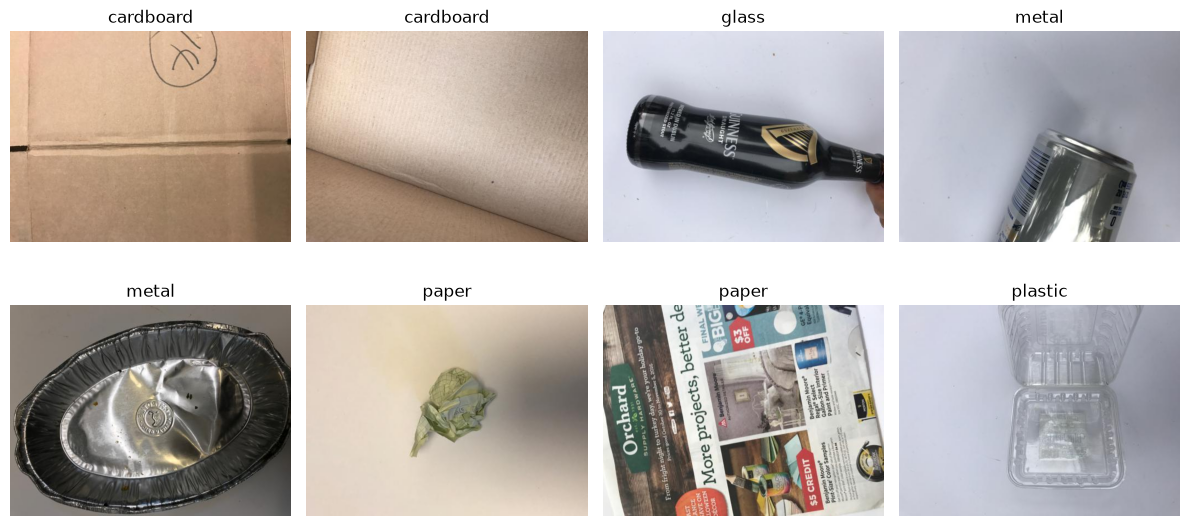

In [1]:
import os
import torch
from torchvision import datasets
import matplotlib.pyplot as plt

DATA_DIR = r"C:\Users\user\.cache\kagglehub\datasets\asdasdasasdas\garbage-classification\versions\2\Garbage classification\Garbage classification"

raw_dataset = datasets.ImageFolder(root=DATA_DIR)

print(f"Количество примеров в датасете: {len(raw_dataset)}")
print(f"Классы: {raw_dataset.classes}")
print(f"Форма одного изображения (Ширина х Высота): {raw_dataset[0][0].size}")
print(f"Тип метки (класса): {type(raw_dataset[0][1])}")


fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

for i in range(8):
    img, label = raw_dataset[i * (len(raw_dataset) // 8)]  # Берём более-менее равномерно по датасету
    axes[i].imshow(img)
    axes[i].set_title(raw_dataset.classes[label])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Делим выборку на обучающую, тестовую и валидационную

In [2]:
from torch.utils.data import random_split

total_size = len(raw_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

# Фиксируем seed для воспроизводимости разделения
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    raw_dataset, [train_size, val_size, test_size], generator=generator
)

print("Размеры выборок после разделения (70/15/15):")
print(f"Train:      {len(train_dataset)} примеров")
print(f"Validation: {len(val_dataset)} примеров")
print(f"Test:       {len(test_dataset)} примеров")

Размеры выборок после разделения (70/15/15):
Train:      1768 примеров
Validation: 379 примеров
Test:       380 примеров


Строим трансформации для данных

In [3]:
from torchvision import transforms

# Стандартные параметры нормализации для моделей, обученных на ImageNet
# Рекомендуются в https://docs.pytorch.org/docs/0.4.1/torchvision/models.html
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Трансформации для тренировочной выборки (с аугментацией в виде случайного отражения + вращения)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

# Трансформации для валидации и теста (без аугментации)
val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

print("Трансформации успешно определены.")

Трансформации успешно определены.


Создаём загрузчики данных

In [4]:
from torch.utils.data import DataLoader

# Применяем трансформации к разделенным датасетам
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        return self.transform(img), label

train_dataset = TransformedSubset(train_dataset, train_transforms)
val_dataset   = TransformedSubset(val_dataset, val_test_transforms)
test_dataset  = TransformedSubset(test_dataset, val_test_transforms)

# Создаем DataLoaders
batch_size = 16
num_workers = 0  # На Windows в Jupyter num_workers>0 использует spawn и пытается
                  # импортировать __main__ (=ядро Jupyter, а не ноутбук) —
                  # воркер не находит класс TransformedSubset и зависает без ошибки

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                           num_workers=num_workers, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                         num_workers=num_workers, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                          num_workers=num_workers, pin_memory=True)

print(f"Размер батча: {batch_size}")
print(f"Количество батчей в Train: {len(train_loader)}")
print(f"Количество батчей в Val: {len(val_loader)}")
print(f"Количество батчей в Test: {len(test_loader)}")

Размер батча: 16
Количество батчей в Train: 111
Количество батчей в Val: 24
Количество батчей в Test: 24


In [12]:
images, labels = next(iter(train_loader))
print("Форма батча изображений:", images.shape)   # [16, 3, 224, 224]
print("Форма одного изображения:", images[0].shape)
print("Форма батча меток:", labels.shape, labels.dtype)

Форма батча изображений: torch.Size([16, 3, 224, 224])
Форма одного изображения: torch.Size([3, 224, 224])
Форма батча меток: torch.Size([16]) torch.int64


2. **Выбор нейросетей, их модификация**

Для работы выбраны 4 легковесные архитектуры, доступные в `torchvision` с весами ImageNet:
1. **ResNet18** — классическая остаточная сеть (skip connections решают проблему затухания градиента).
2. **MobileNetV2** — использует depthwise separable convolutions, очень быстрая и легкая.
3. **EfficientNet-B0** — использует метод масштабирования (compound scaling), показывая высокую точность при малом числе параметров.
4. **DenseNet121** — каждый слой соединен со всеми последующими, что отлично работает на малых датасетах.

**Модификация:** Так как исходные модели обучены на 1000 классов ImageNet, мы заменим их финальные полносвязные слои-классификаторы на новые, выдающие 6 выходов по числу наших классов.

In [5]:
import torchvision.models as models
import torch.nn as nn

def get_modified_model(model_name, pretrained=False, num_classes=6):
    """
    Создает выбранную архитектуру и модифицирует последний слой под num_classes.
    Если pretrained=True, загружает веса ImageNet.
    """
    weights = 'DEFAULT' if pretrained else None
    
    if model_name == 'resnet18':
        model = models.resnet18(weights=weights)
        # В ResNet последний слой называется fc
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        
    elif model_name == 'mobilenet_v2':
        model = models.mobilenet_v2(weights=weights)
        # В MobileNet классификатор — это Sequential, берем последний Linear
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        
    elif model_name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=weights)
        # В EfficientNet аналогично MobileNet
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        
    elif model_name == 'densenet121':
        model = models.densenet121(weights=weights)
        # В DenseNet последний слой называется classifier
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)
        
    else:
        raise ValueError(f"Неизвестная модель: {model_name}")
        
    return model

# Список названий наших моделей для последующих циклов
MODEL_NAMES = ['resnet18', 'mobilenet_v2', 'efficientnet_b0', 'densenet121']

3. **Выбор функции потерь, оптимизатора и гиперпараметров обучения**

In [6]:
import torch.nn as nn
import torch.optim as optim

# Функция потерь - кросс-энтропия
criterion = nn.CrossEntropyLoss()
print(f"Функция потерь: {criterion}")

# 2. Гиперпараметры
NUM_EPOCHS = 10 # Всего 10 эпох
LR_SCRATCH = 1e-3   # Для обучения с нуля
LR_PRETRAINED = 1e-4 # Для fine-tuning (меньше, чтобы не ломать веса)

# 3. Функция для создания оптимизатора и планировщика
def get_optimizer_and_scheduler(model, lr):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    # Уменьшаем шаг в 10 раз каждые 4 эпохи
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=4, gamma=0.1)
    return optimizer, scheduler

print(f"Количество эпох: {NUM_EPOCHS}")
print(f"LR для обучения с нуля: {LR_SCRATCH}")
print(f"LR для переноса знаний: {LR_PRETRAINED}")
print("Оптимизатор: Adam, планировщик: StepLR (step_size=4, gamma=0.1)")

Функция потерь: CrossEntropyLoss()
Количество эпох: 10
LR для обучения с нуля: 0.001
LR для переноса знаний: 0.0001
Оптимизатор: Adam, планировщик: StepLR (step_size=4, gamma=0.1)


4. **Обучение и валидация**

In [7]:
from tqdm.auto import tqdm
from sklearn.metrics import f1_score

# Запуск ОДНОЙ эпохи обучения
def train_one_epoch(model, dataloader, criterion, optimizer, scaler, device):
    model.train()
    running_loss = 0.0
    
    for images, labels in tqdm(dataloader, desc="Train", leave=False):
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        # Включаем Mixed Precision для прямого прохода
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)
            
        # Масштабируем градиенты и делаем шаг
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        running_loss += loss.item() * images.size(0)
        
    return running_loss / len(dataloader.dataset)

# Оценка полученной модели на валидационной выборке
def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc="Eval", leave=False):
            images, labels = images.to(device), labels.to(device)
            
            # Включаем Mixed Precision для инференса
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                outputs = model(images)
                loss = criterion(outputs, labels)
                
            running_loss += loss.item() * images.size(0)
            
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    epoch_loss = running_loss / len(dataloader.dataset)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    return epoch_loss, macro_f1

Полный цикл обучения для одной модели

In [8]:
def run_experiment(model_name, pretrained=False):
    print(f"\n=== Запуск эксперимента: {model_name} | Pretrained: {pretrained} ===")
    device = 'cuda'
    model = get_modified_model(model_name, pretrained=pretrained, num_classes=6)
    model = model.to(device)
    
    lr = LR_PRETRAINED if pretrained else LR_SCRATCH
    optimizer, scheduler = get_optimizer_and_scheduler(model, lr)
    
    # Создаем GradScaler для AMP
    scaler = torch.amp.GradScaler('cuda')
    
    history = {'train_loss': [], 'val_loss': [], 'val_f1': []}
    
    for epoch in range(NUM_EPOCHS):
        # Передаем scaler в функцию обучения
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device)
        val_loss, val_f1 = evaluate(model, val_loader, criterion, device)
        
        scheduler.step()
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_f1'].append(val_f1)
        
        print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val Macro F1: {val_f1:.4f}")
    test_loss, test_f1 = evaluate(model, test_loader, criterion, device)
    history['test_loss'] = test_loss
    history['test_f1'] = test_f1
    print(f"TEST  | Loss: {test_loss:.4f} | Macro F1: {test_f1:.4f}")
    return model, history

Запуск обучения для всех моделей и конфигураций

In [9]:
import json, os
import torch
import gc

# Список всех архитектур для эксперимента
ALL_MODELS = ['resnet18', 'mobilenet_v2', 'efficientnet_b0', 'densenet121']

# Словарь для сохранения всей истории обучения (метрики по эпохам)
all_histories = {}

print("=== СТАРТ ПОЛНОГО ЦИКЛА ЭКСПЕРИМЕНТОВ (8 моделей) ===")


os.makedirs("checkpoints", exist_ok=True)
RESULTS_PATH = "all_histories.json"

all_histories = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}

for model_name in ALL_MODELS:
    for pretrained in [False, True]:
        mode = 'pretrained' if pretrained else 'scratch'
        key = f"{model_name}_{mode}"
        if key in all_histories:
            print(f"Пропускаем {key} — уже посчитано")
            continue
        try:
            model, history = run_experiment(model_name, pretrained=pretrained)
            torch.save(model.state_dict(), f"checkpoints/{key}.pth")
            all_histories[key] = history
        except RuntimeError as e:
            print(f"{key} упал: {e}")
        finally:
            torch.cuda.empty_cache()
            gc.collect()
        json.dump(all_histories, open(RESULTS_PATH, "w"), indent=2)

print("\n=== ВСЕ 8 ЭКСПЕРИМЕНТОВ УСПЕШНО ЗАВЕРШЕНЫ ===")
print("Доступные истории обучения:")
for key in all_histories.keys():
    print(f" - {key}")

=== СТАРТ ПОЛНОГО ЦИКЛА ЭКСПЕРИМЕНТОВ (8 моделей) ===

=== Запуск эксперимента: resnet18 | Pretrained: False ===


Train:   0%|          | 0/111 [00:00<?, ?it/s]

Eval:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 1.5316 | Val Loss: 1.6494 | Val Macro F1: 0.3439


Train:   0%|          | 0/111 [00:00<?, ?it/s]

Eval:   0%|          | 0/24 [00:00<?, ?it/s]

... (248 outputs left out)

Eval:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.0610 | Val Loss: 0.1784 | Val Macro F1: 0.9339


Eval:   0%|          | 0/24 [00:00<?, ?it/s]

TEST  | Loss: 0.1569 | Macro F1: 0.9359

=== ВСЕ 8 ЭКСПЕРИМЕНТОВ УСПЕШНО ЗАВЕРШЕНЫ ===
Доступные истории обучения:
 - resnet18_scratch
 - resnet18_pretrained
 - mobilenet_v2_scratch
 - mobilenet_v2_pretrained
 - efficientnet_b0_scratch
 - efficientnet_b0_pretrained
 - densenet121_scratch
 - densenet121_pretrained


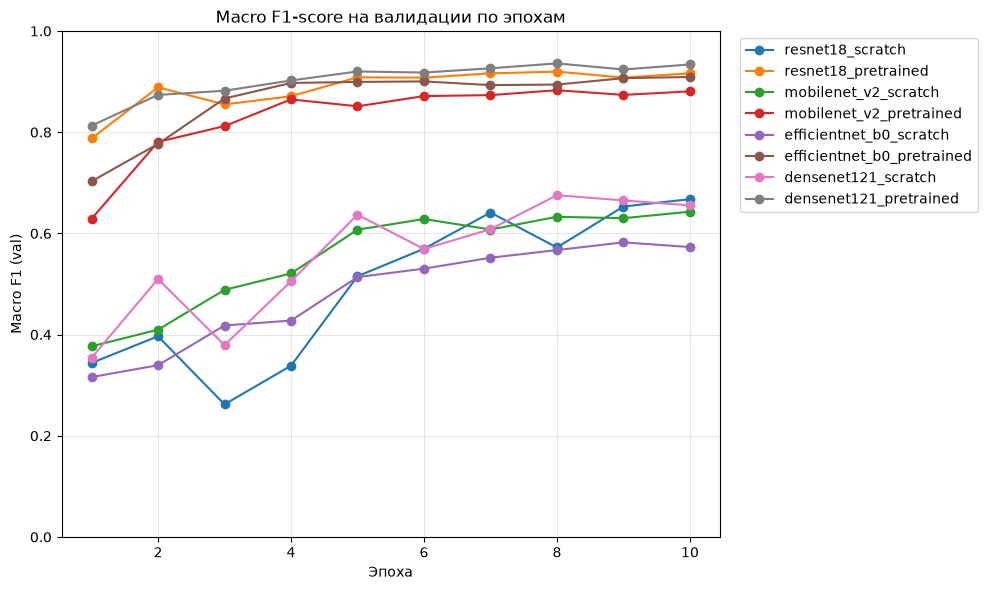

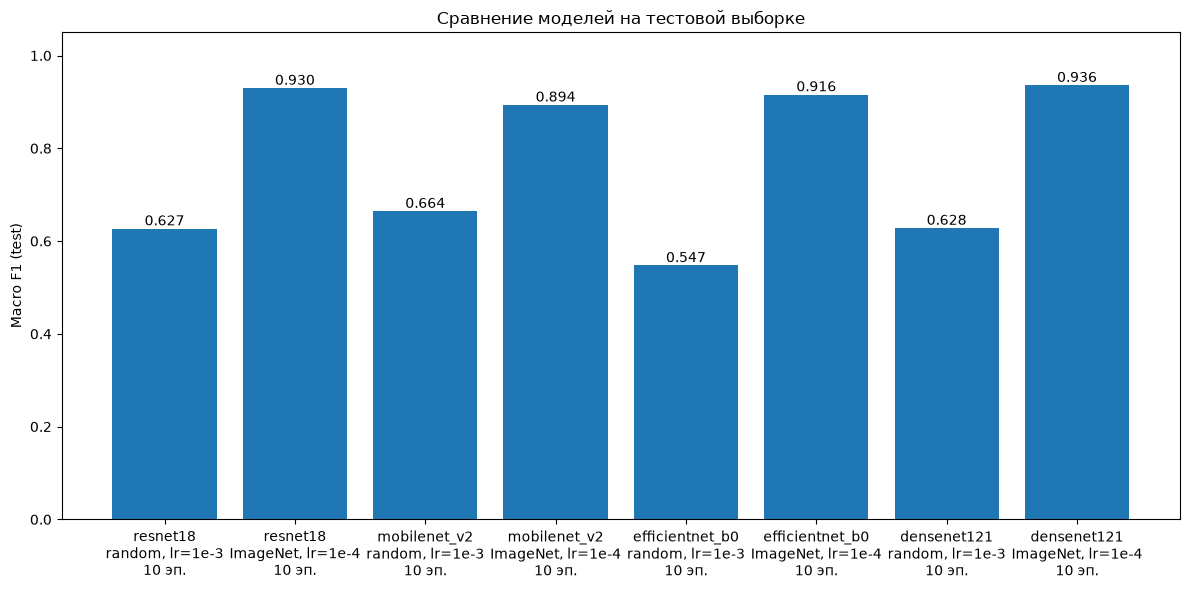

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for key, history in all_histories.items():
    plt.plot(range(1, NUM_EPOCHS + 1), history['val_f1'], marker='o', label=key)
plt.xlabel("Эпоха"); plt.ylabel("Macro F1 (val)")
plt.title("Macro F1-score на валидации по эпохам")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

keys = list(all_histories.keys())
test_f1s = [all_histories[k]['test_f1'] for k in keys]
labels_x = [f"{k.rsplit('_',1)[0]}\n{'ImageNet, lr=1e-4' if k.endswith('pretrained') else 'random, lr=1e-3'}\n{NUM_EPOCHS} эп."
            for k in keys]

plt.figure(figsize=(12, 6))
bars = plt.bar(labels_x, test_f1s)
plt.bar_label(bars, fmt='%.3f')
plt.ylim(0, 1.05)
plt.ylabel("Macro F1 (test)")
plt.title("Сравнение моделей на тестовой выборке")
plt.tight_layout(); plt.show()